In [ ]:
!pip install roboflow ultralytics

import matplotlib.pyplot as plt
import numpy as np
from roboflow import Roboflow
import os

rf = Roboflow(api_key="TkOu1KkaaAOMzeprhbrO")
project = rf.workspace("sara-dhaif").project("bahrain_foods-dyyn5")
version = project.version(2)
dataset = version.download("yolo26")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 124.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 82.1 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bahrain_Foods-2 in yolo26:: 100%|██████████| 1161/1161 [00:00<00:00, 8158.84it/s]


In [ ]:
# ● Number of images containing each class.
# ● Average number of objects per image.
# ● Examples of good annotations.
# ● Examples of questionable annotations.
# ● Any obvious class imbalance.

In [ ]:
# Number of images in train / validation / test ✅.

In [ ]:
images_train = os.listdir("/content/Bahrain_Foods-1/train/images")
len(images_train)

600

In [ ]:
images_val = os.listdir("/content/Bahrain_Foods-1/valid/images")
len(images_val)

86

In [ ]:
images_test = os.listdir("/content/Bahrain_Foods-1/test/images")
len(images_test)

43

In [ ]:
from collections import Counter

In [ ]:
import pandas as pd
import glob

labels = glob.glob("/content/Bahrain_Foods-1/train/labels/*.txt")

classes = []

for file in labels:
    for line in open(file):
        if line.strip():
            classes.append(int(line.split()[0]))

pd.Series(classes).value_counts().sort_index()

,count
0,188
1,75
2,40
3,42
4,48
5,46
6,42
7,139
8,88
9,58


In [ ]:
from ultralytics import YOLO
model = YOLO("yolo26s.pt")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
model.train(data = "/content/Bahrain_Foods-2/data.yaml", epochs = 10)


Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bahrain_Foods-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, op

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b17542985f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0470


image 1/1 /content/Bahrain_Foods-2/test/images/Balaleet_5_jpeg.rf.97a82b1b9869a6138f303dc0c6ef255a.jpg: 640x480 1 balaleet, 20.4ms
Speed: 2.3ms preprocess, 20.4ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)


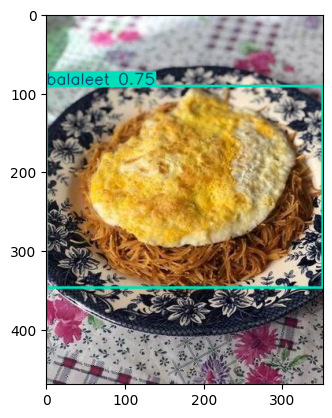

In [ ]:
fintuned_model = YOLO("/content/runs/detect/train/weights/best.pt")

results = fintuned_model("/content/Bahrain_Foods-2/test/images/Balaleet_5_jpeg.rf.97a82b1b9869a6138f303dc0c6ef255a.jpg")
plt.imshow(results[0].plot()[...,::-1])


image 1/1 /content/Bahrain_Foods-2/test/images/Nakhaj3_jpg.rf.a1d145be07c884f097f3477e46d67551.jpg: 640x640 2 nakhajs, 54.6ms
Speed: 2.1ms preprocess, 54.6ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


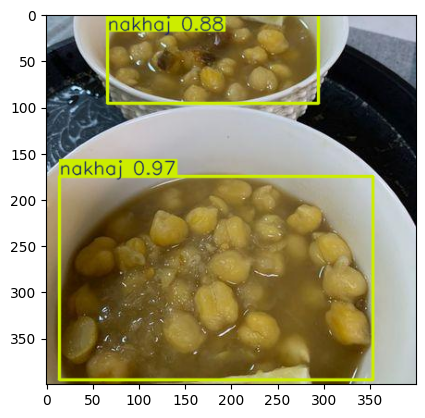

In [ ]:
results = fintuned_model("/content/Bahrain_Foods-2/test/images/Nakhaj3_jpg.rf.a1d145be07c884f097f3477e46d67551.jpg")
plt.imshow(results[0].plot()[...,::-1])


image 1/1 /content/Bahrain_Foods-2/test/images/Tikka_5_jpeg.rf.a2fbdc205821d45b23a403b161531b0e.jpg: 640x640 1 tikka, 23.7ms
Speed: 2.7ms preprocess, 23.7ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


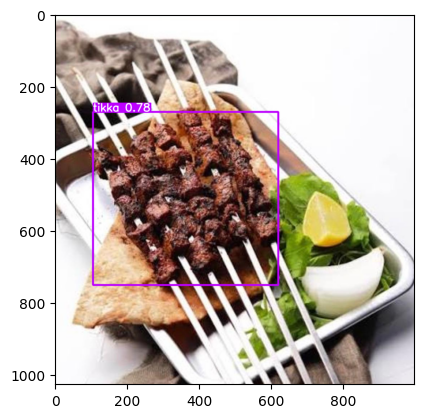

In [ ]:
results = fintuned_model("/content/Bahrain_Foods-2/test/images/Tikka_5_jpeg.rf.a2fbdc205821d45b23a403b161531b0e.jpg")
plt.imshow(results[0].plot()[...,::-1])

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1607.8±453.0 MB/s, size: 70.1 KB)
val: Scanning /content/Bahrain_Foods-2/test/labels... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 1.3Kit/s 0.0s
val: New cache created: /content/Bahrain_Foods-2/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 36, len(boxes) = 39. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.2it/s 1.4s
                   all         34         39      0.865      0.893      0.929      0.827
                 Halwa          6          7        0.9      0.857  

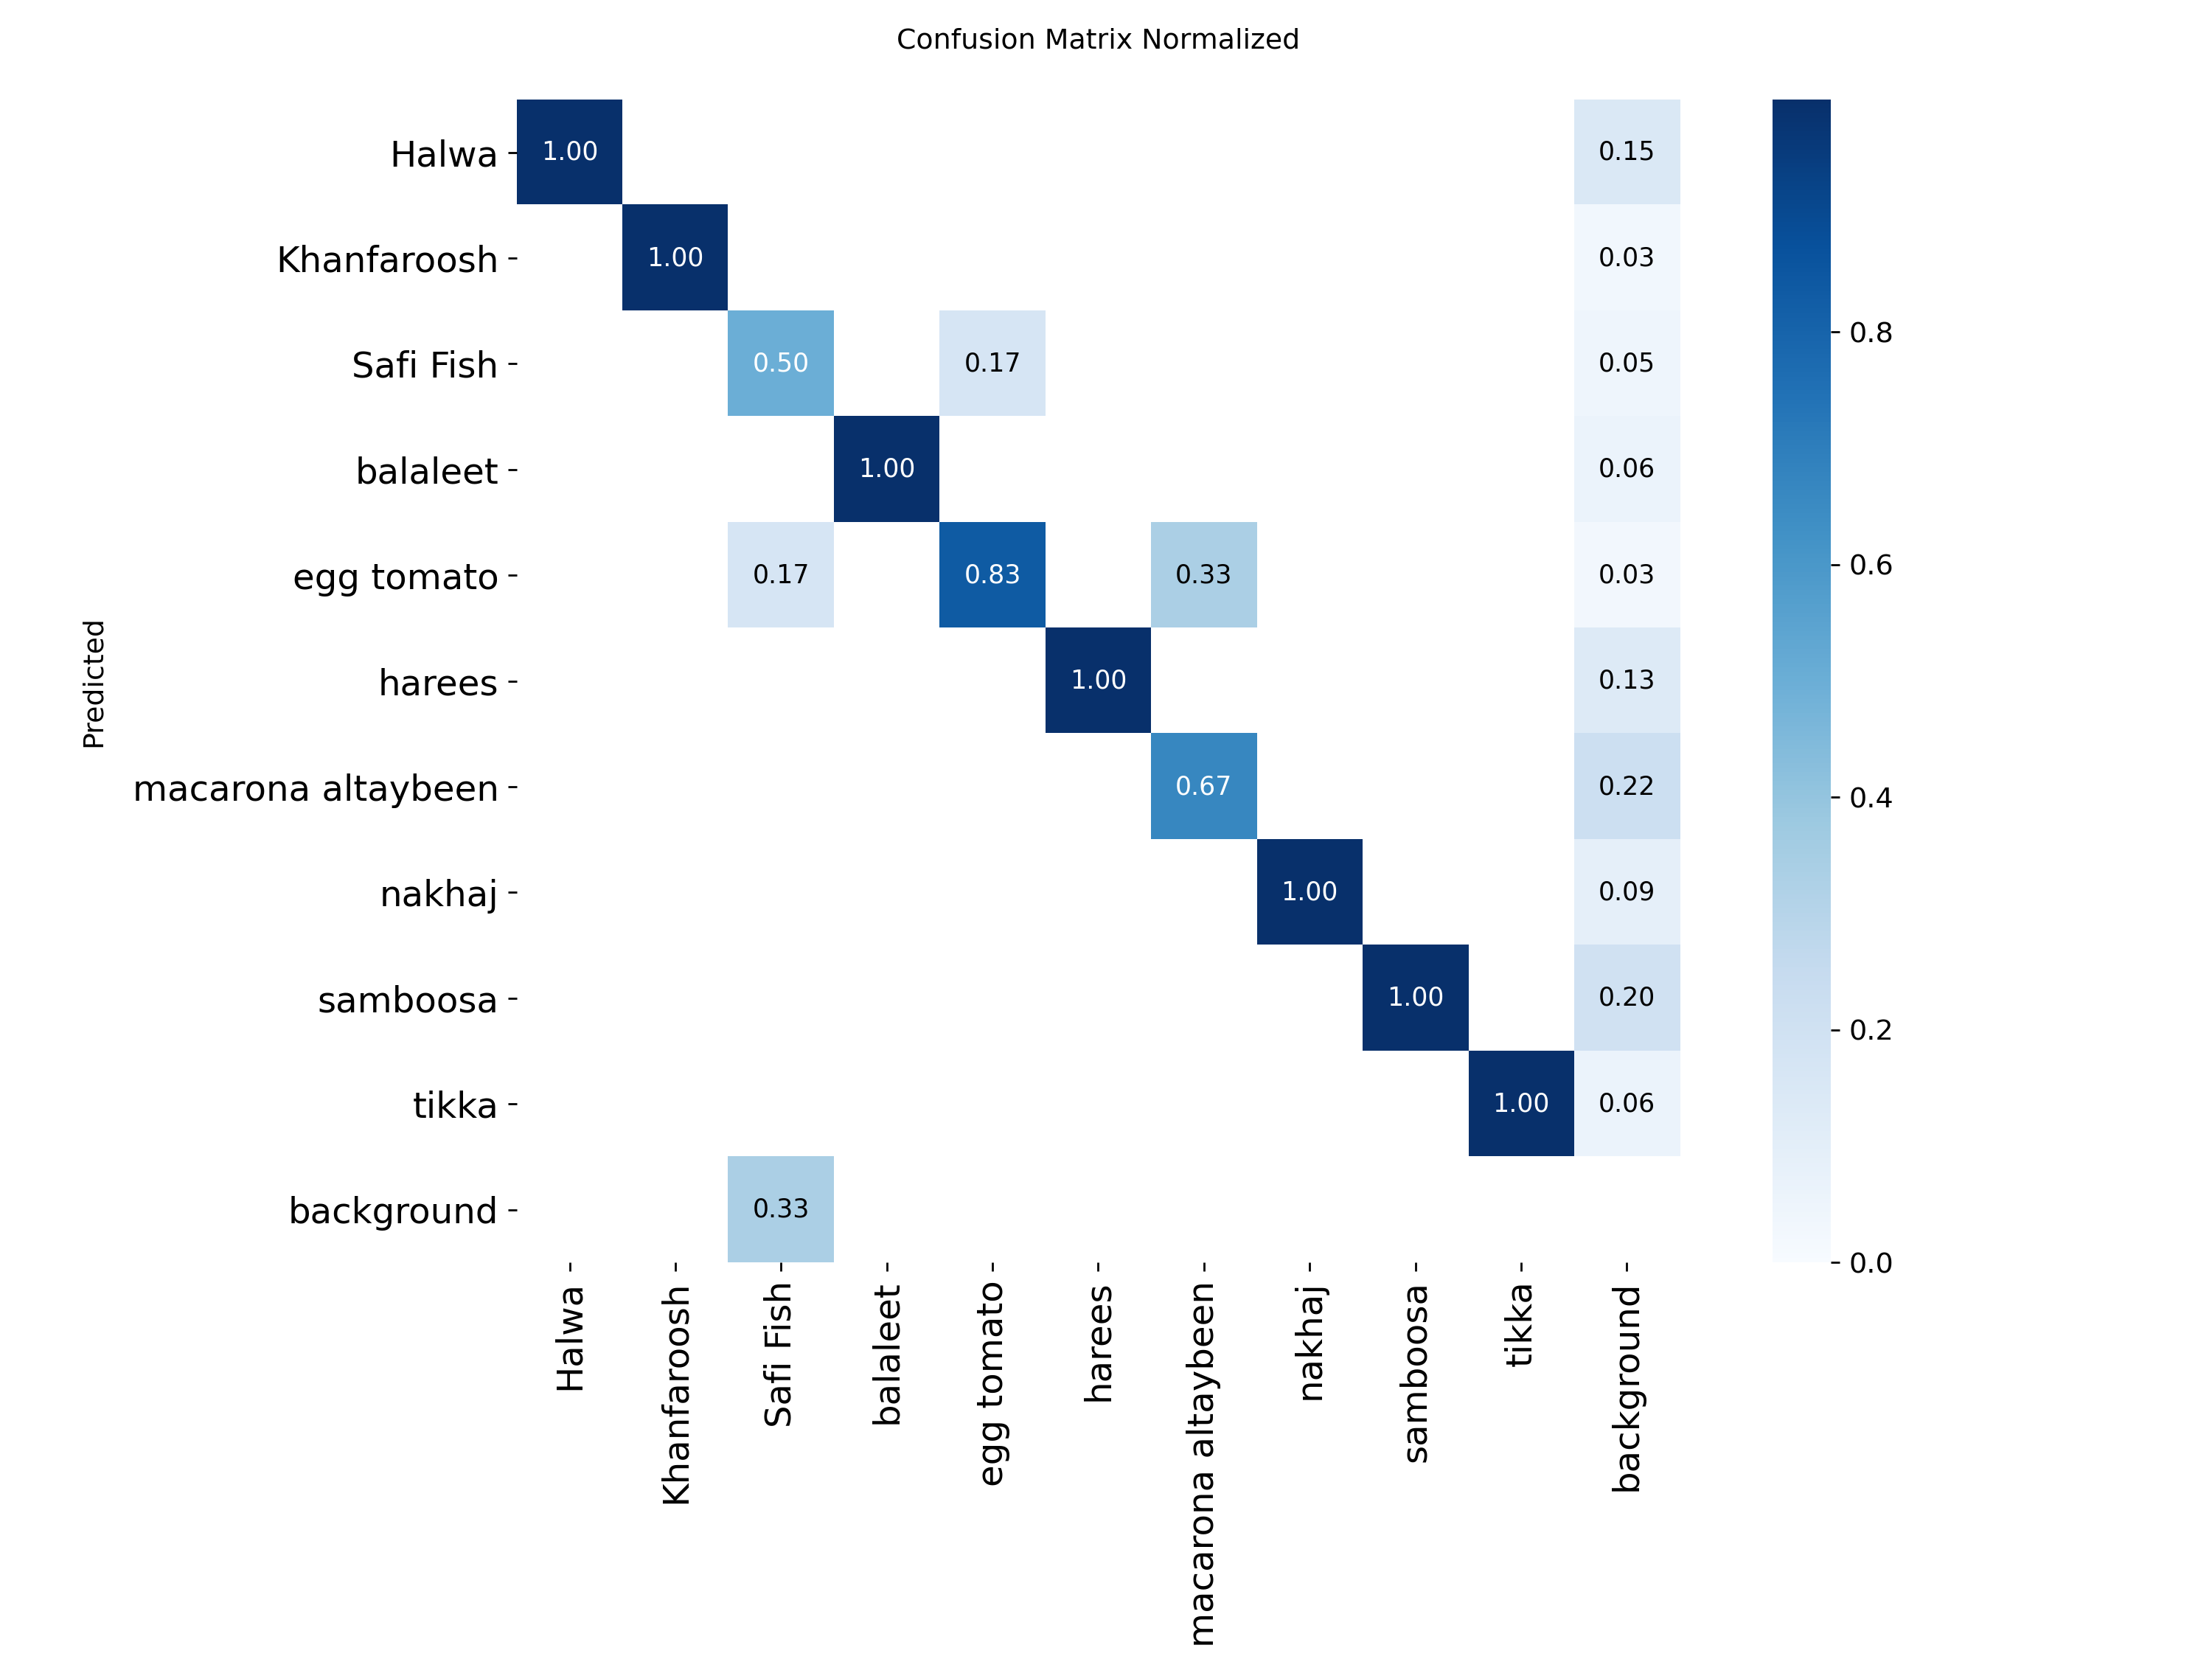

In [ ]:
## Evaluation
from IPython.display import Image, display
# per class performance
metrics = fintuned_model.val(data="/content/Bahrain_Foods-2/data.yaml", split="test")
# precision
print("Precision:", metrics.box.mp)
# recall
print("Recall:", metrics.box.mr)
# confision matrix
display(Image(f"{metrics.save_dir}/confusion_matrix_normalized.png"))

In [ ]:
fintuned_model_1 = YOLO("/content/runs/detect/train/weights/last.pt")
fintuned_model_1.train(data = "/content/Bahrain_Foods-2/data.yaml", epochs = 10)


Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bahrain_Foods-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/train/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=No

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b15f8552ad0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0470

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1844.5±527.1 MB/s, size: 70.1 KB)
val: Scanning /content/Bahrain_Foods-2/test/labels.cache... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 7.9Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 36, len(boxes) = 39. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.3it/s 1.3s
                   all         34         39       0.79      0.902      0.946      0.828
                 Halwa          6          7      0.579      0.857      0.862      0.792
           Khanfaroosh          1       

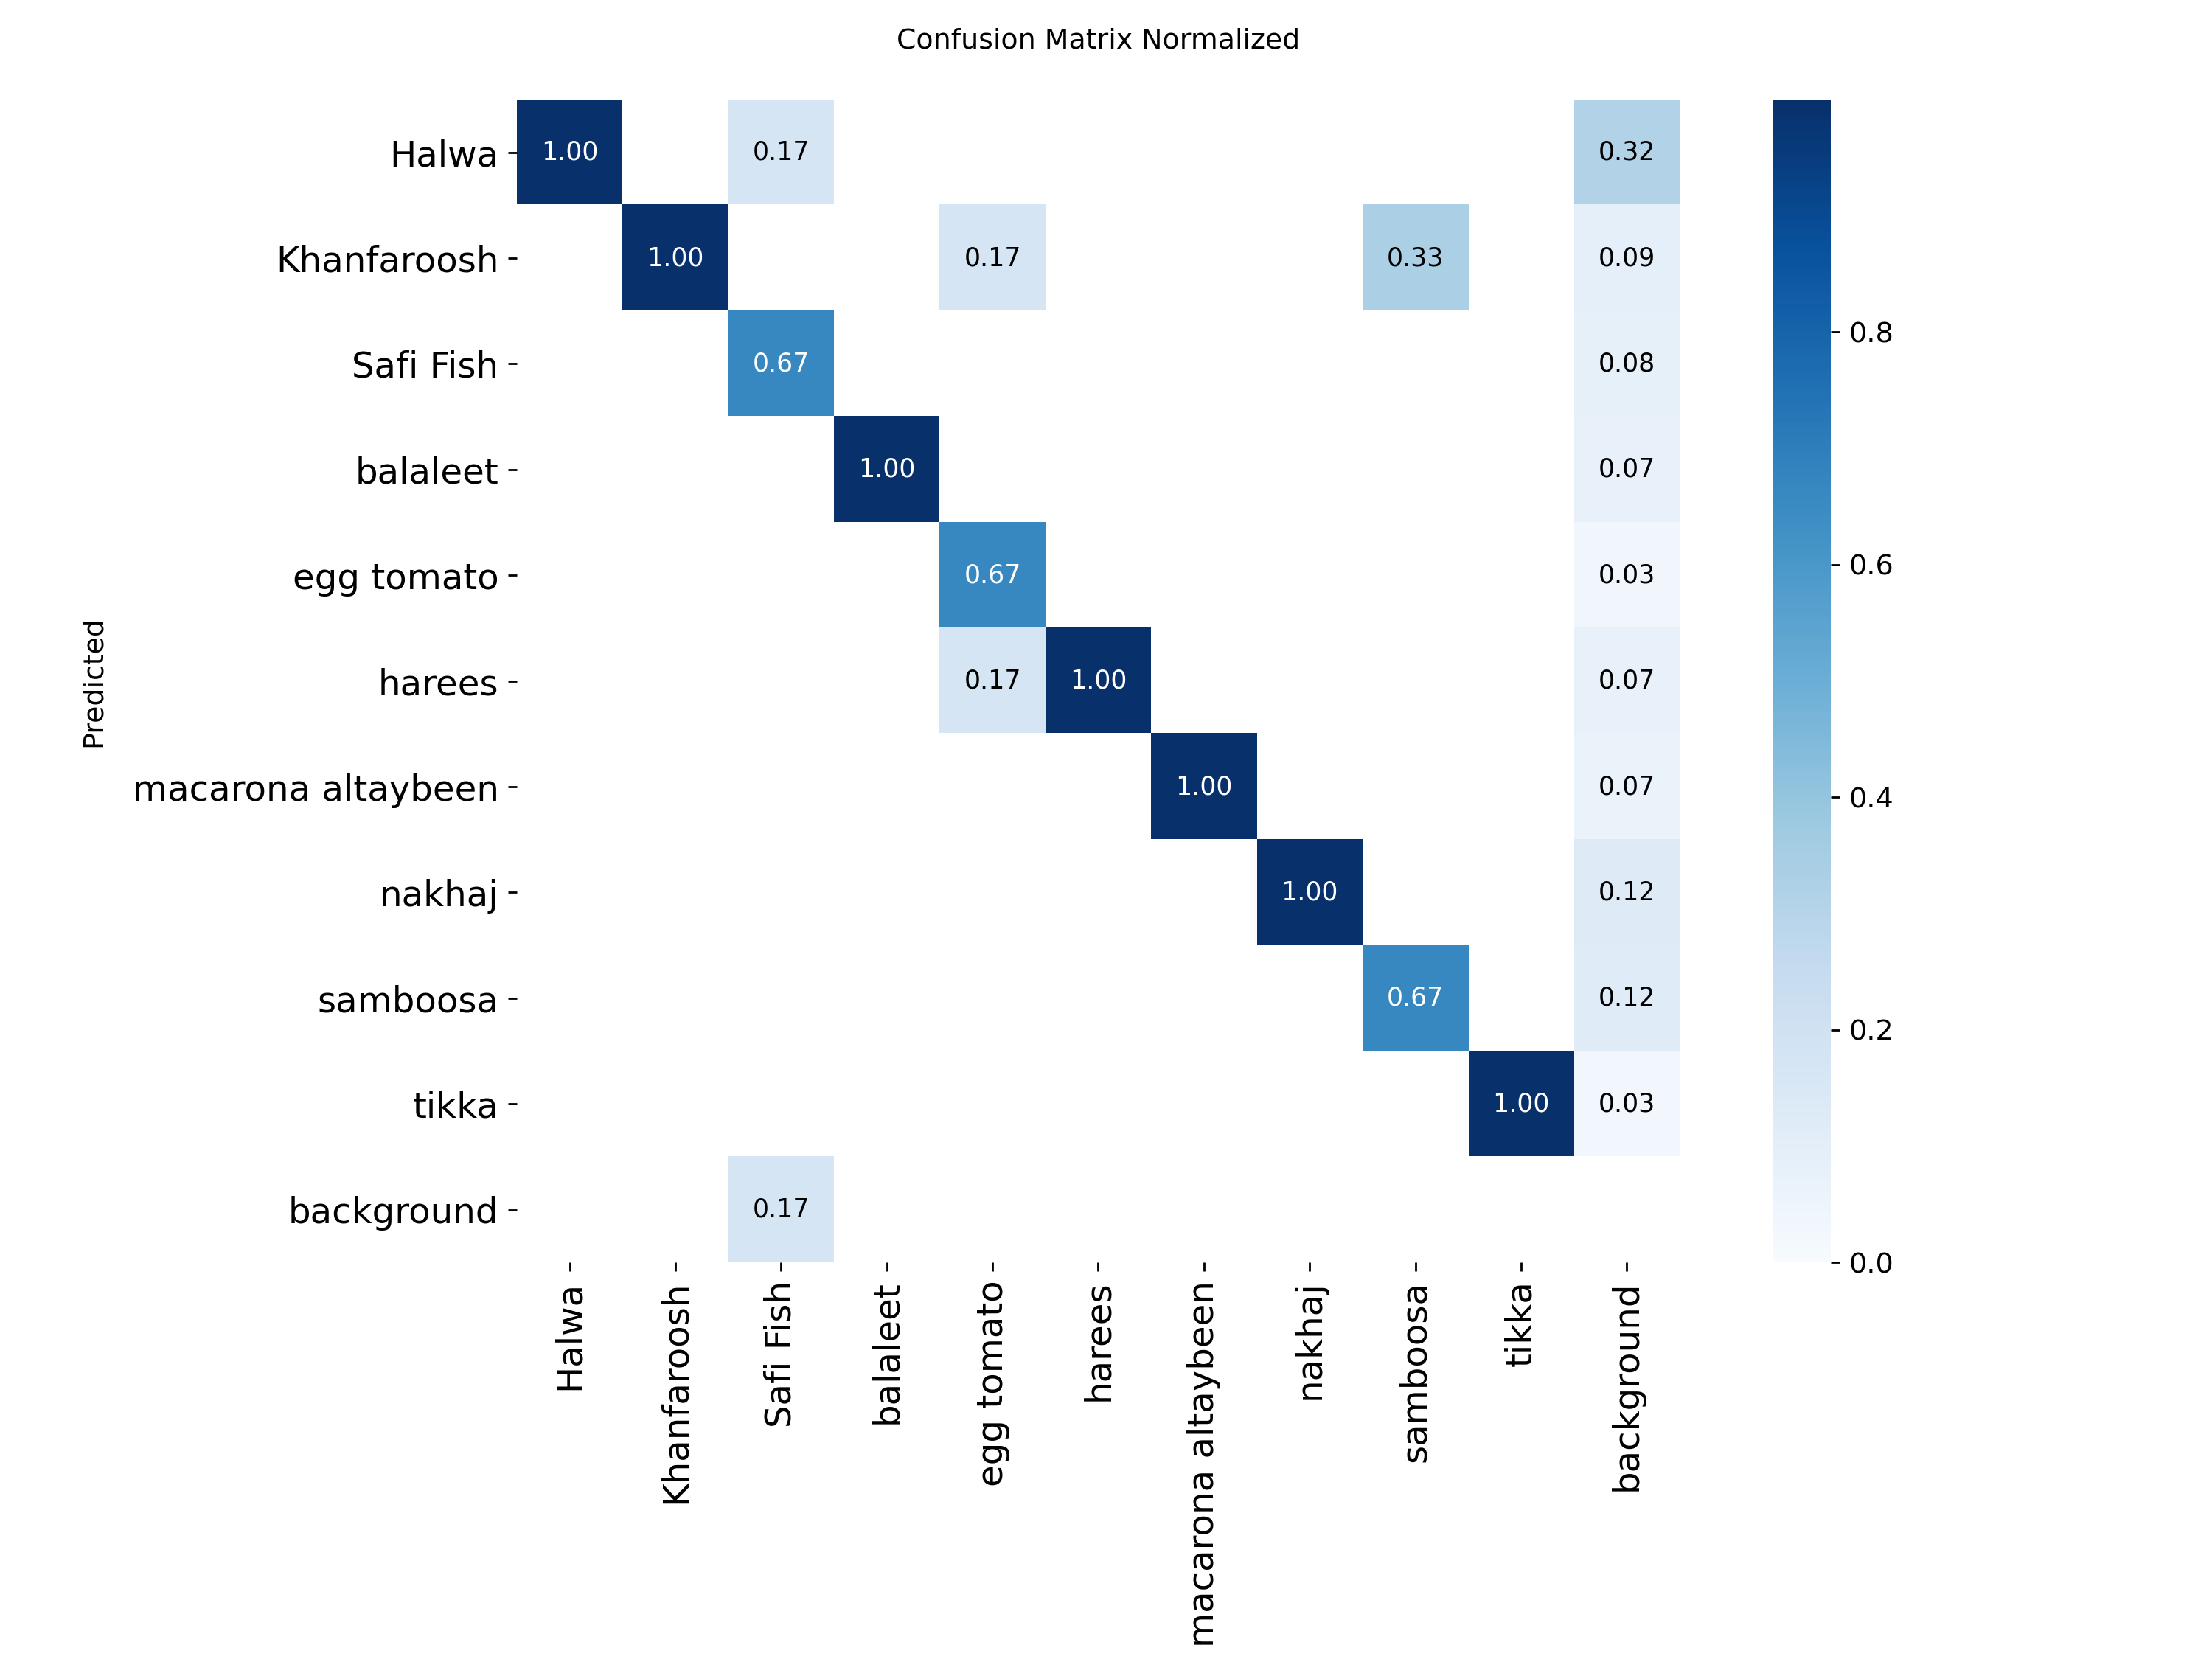

In [ ]:
## Evaluation
from IPython.display import Image, display
# per class performance
metrics = fintuned_model_1.val(data="/content/Bahrain_Foods-2/data.yaml", split="test")
# precision
print("Precision:", metrics.box.mp)
# recall
print("Recall:", metrics.box.mr)
# confision matrix
display(Image(f"{metrics.save_dir}/confusion_matrix_normalized.png"))

In [ ]:
fintuned_model_2 = YOLO("/content/runs/detect/train-2/weights/last.pt")
fintuned_model_2.train(data = "/content/Bahrain_Foods-2/data.yaml", epochs = 30)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bahrain_Foods-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/train-2/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b15f9739470>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0470

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1524.0±754.2 MB/s, size: 70.1 KB)
val: Scanning /content/Bahrain_Foods-2/test/labels.cache... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 14.3Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 36, len(boxes) = 39. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.1it/s 1.4s
                   all         34         39      0.927      0.928      0.954      0.853
                 Halwa          6          7      0.983      0.857      0.964      0.854
           Khanfaroosh          1      

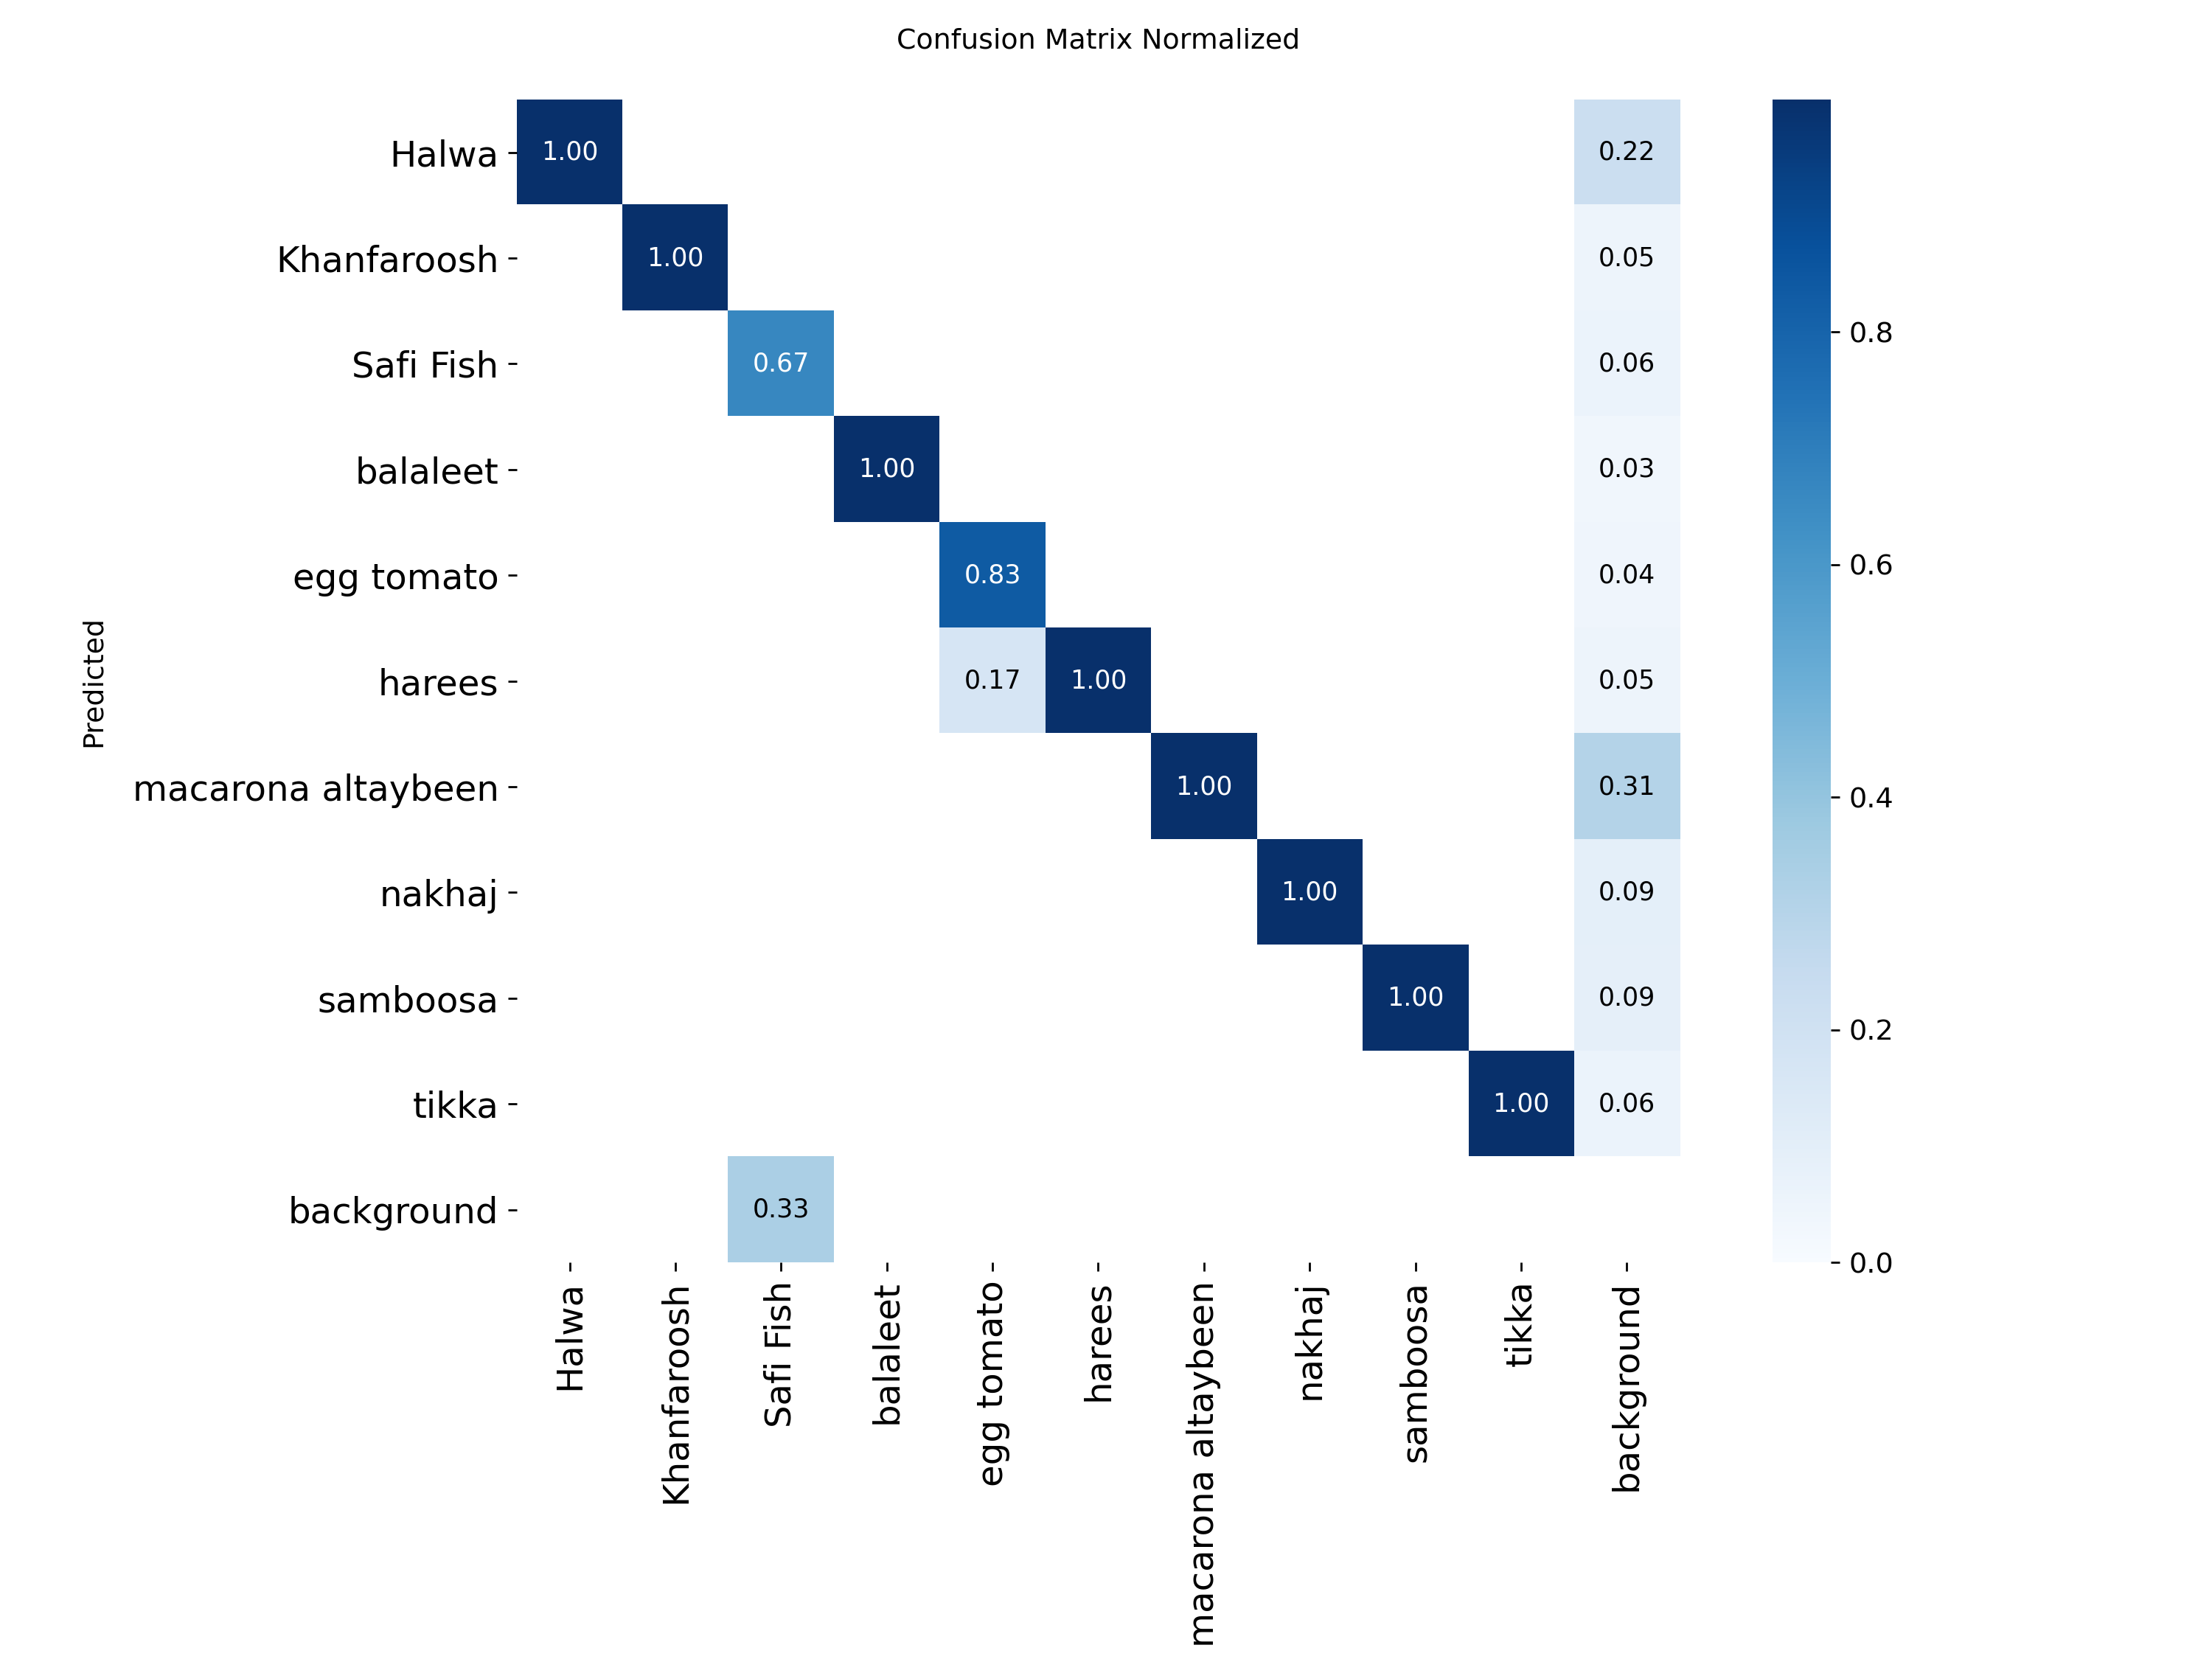

In [ ]:
## Evaluation
from IPython.display import Image, display
# per class performance
metrics = fintuned_model_2.val(data="/content/Bahrain_Foods-2/data.yaml", split="test")
# precision
print("Precision:", metrics.box.mp)
# recall
print("Recall:", metrics.box.mr)
# confision matrix
display(Image(f"{metrics.save_dir}/confusion_matrix_normalized.png"))

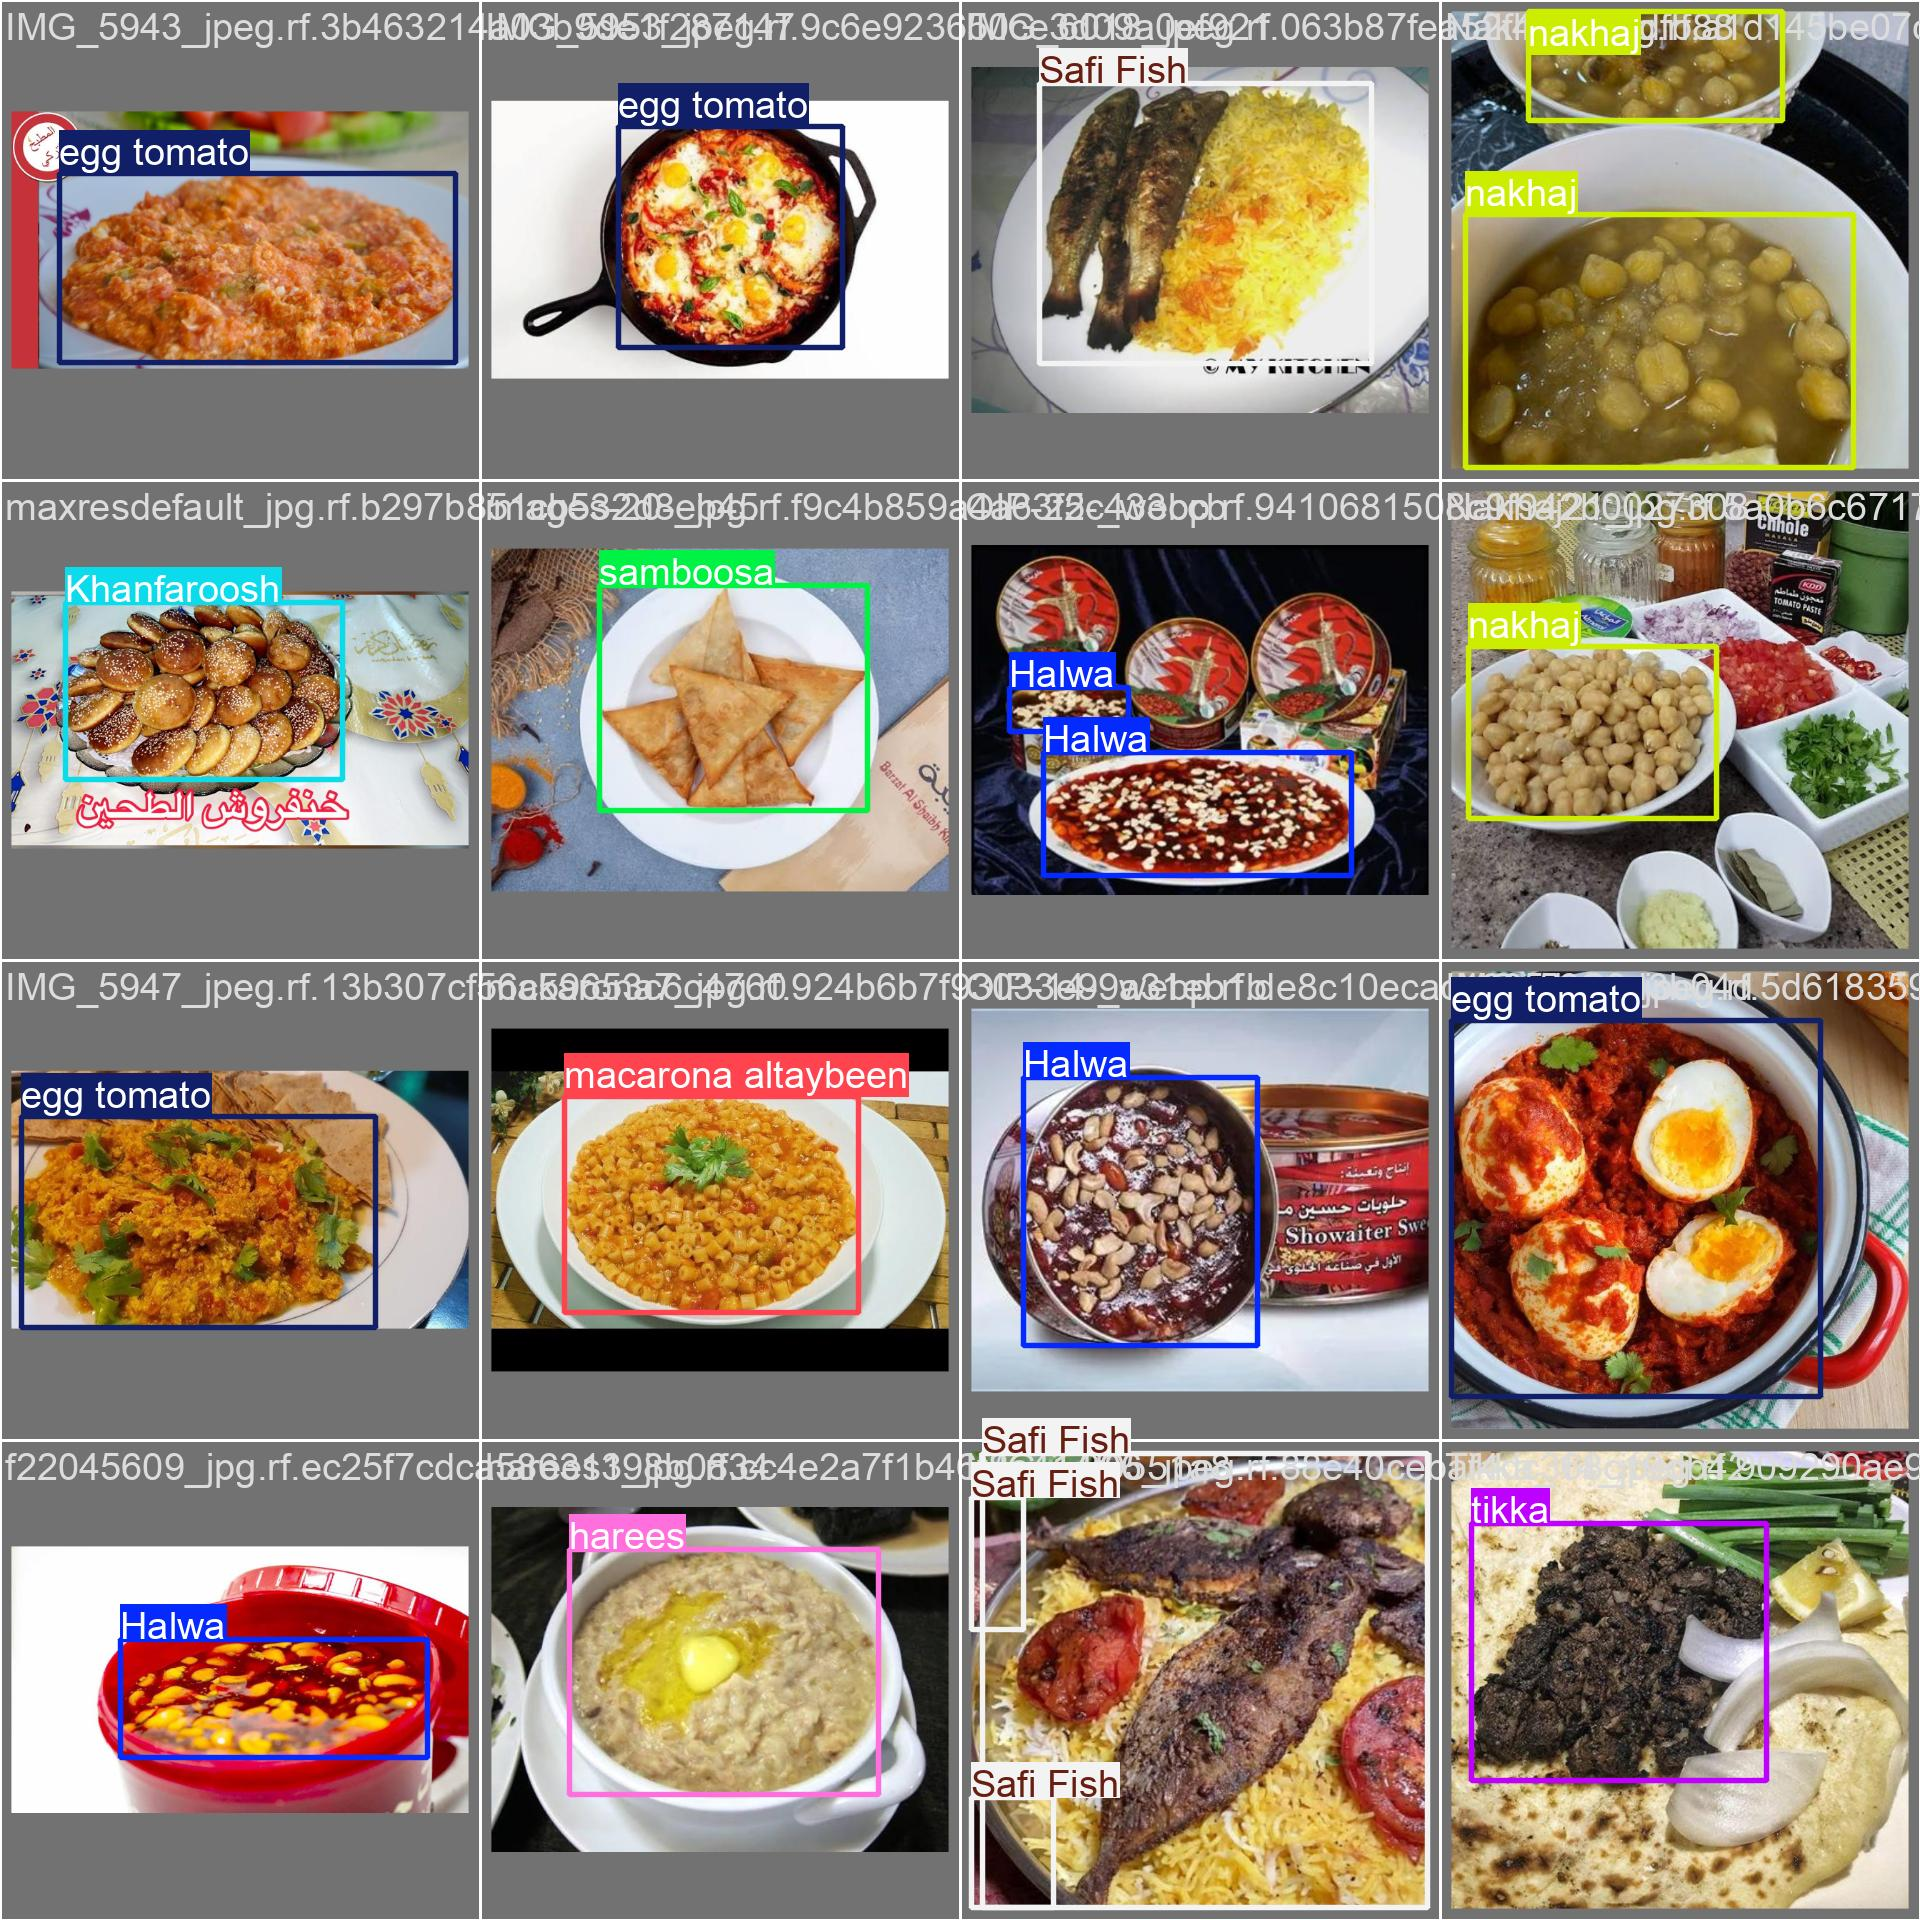

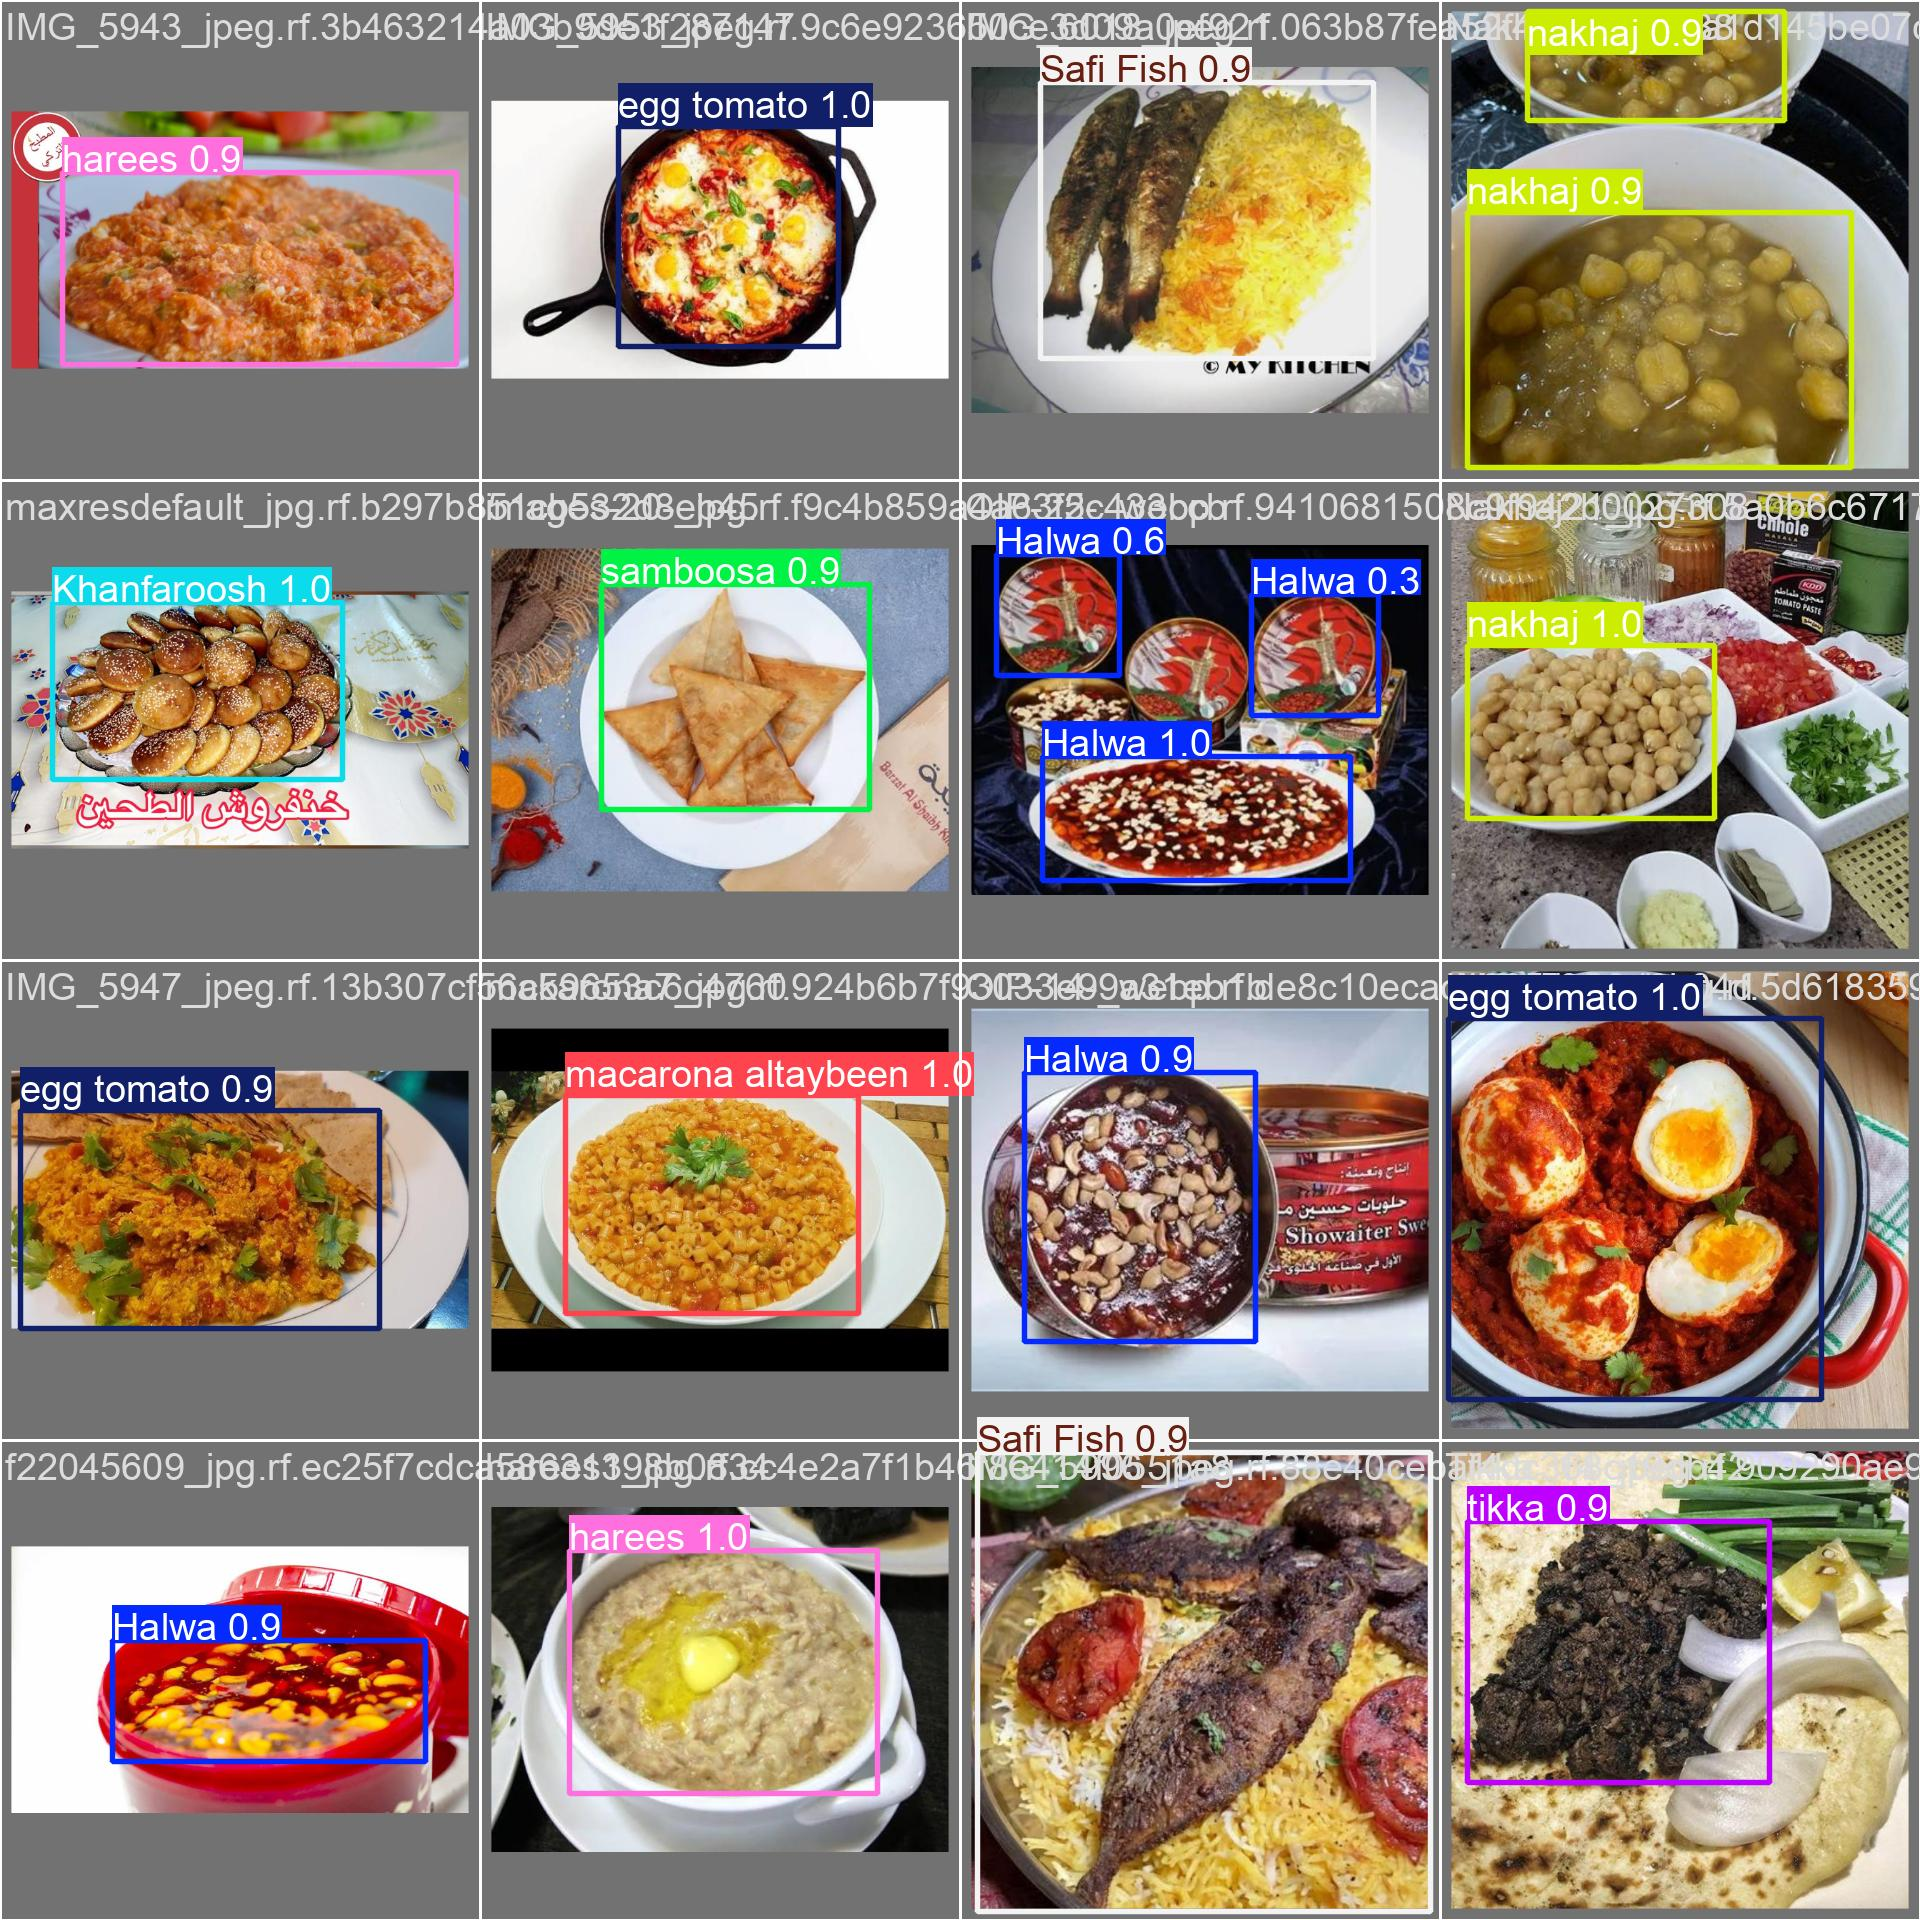

In [ ]:
display(Image(f"{metrics.save_dir}/val_batch0_labels.jpg"))  # true labels
display(Image(f"{metrics.save_dir}/val_batch0_pred.jpg"))    # predictions

6 wrong images


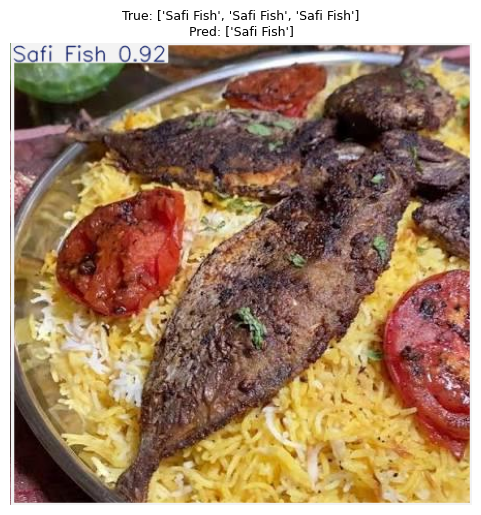

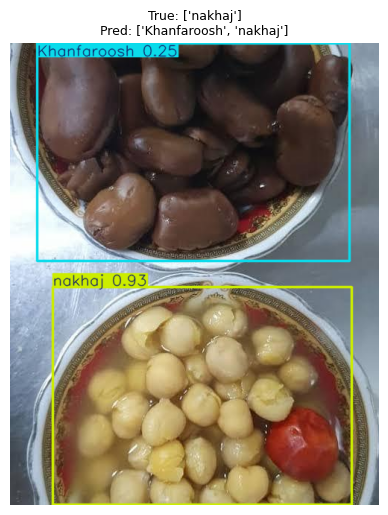

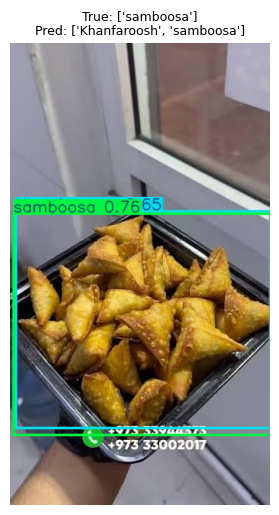

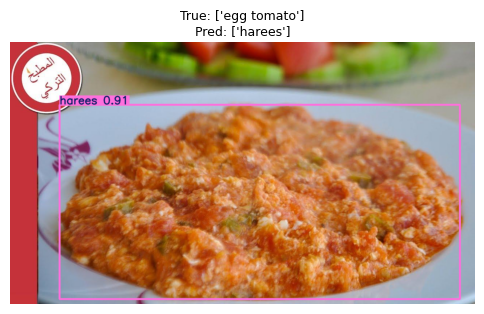

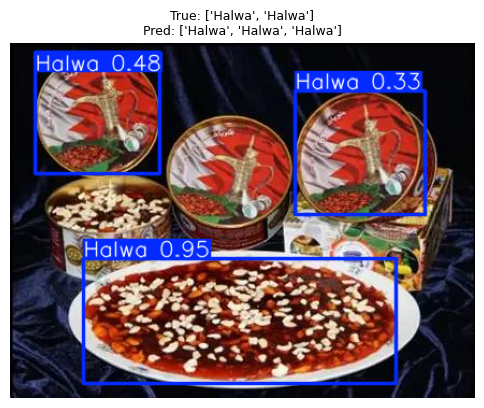

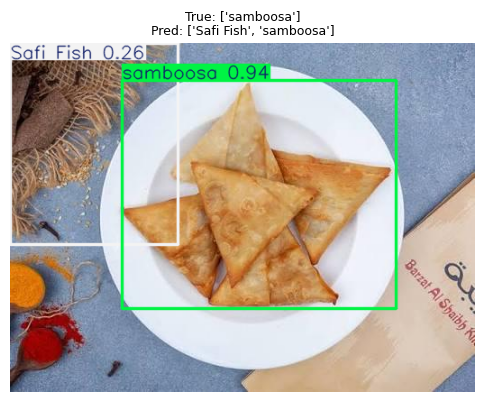

In [ ]:
import os, random, matplotlib.pyplot as plt

names = fintuned_model_2.names
wrong = []
for r in fintuned_model_2.predict("/content/Bahrain_Foods-2/test/images", conf=0.25, stream=True, verbose=False):
    lbl = r.path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    gt = sorted(int(l.split()[0]) for l in open(lbl)) if os.path.exists(lbl) else []
    pr = sorted(r.boxes.cls.int().tolist())
    if gt != pr:
        wrong.append((r.plot()[..., ::-1], [names[i] for i in gt], [names[i] for i in pr]))

print(len(wrong), "wrong images")
for img, gt, pr in random.sample(wrong, min(6, len(wrong))):
    plt.figure(figsize=(6, 6)); plt.imshow(img); plt.axis("off")
    plt.title(f"True: {gt}\nPred: {pr}", fontsize=9); plt.show()

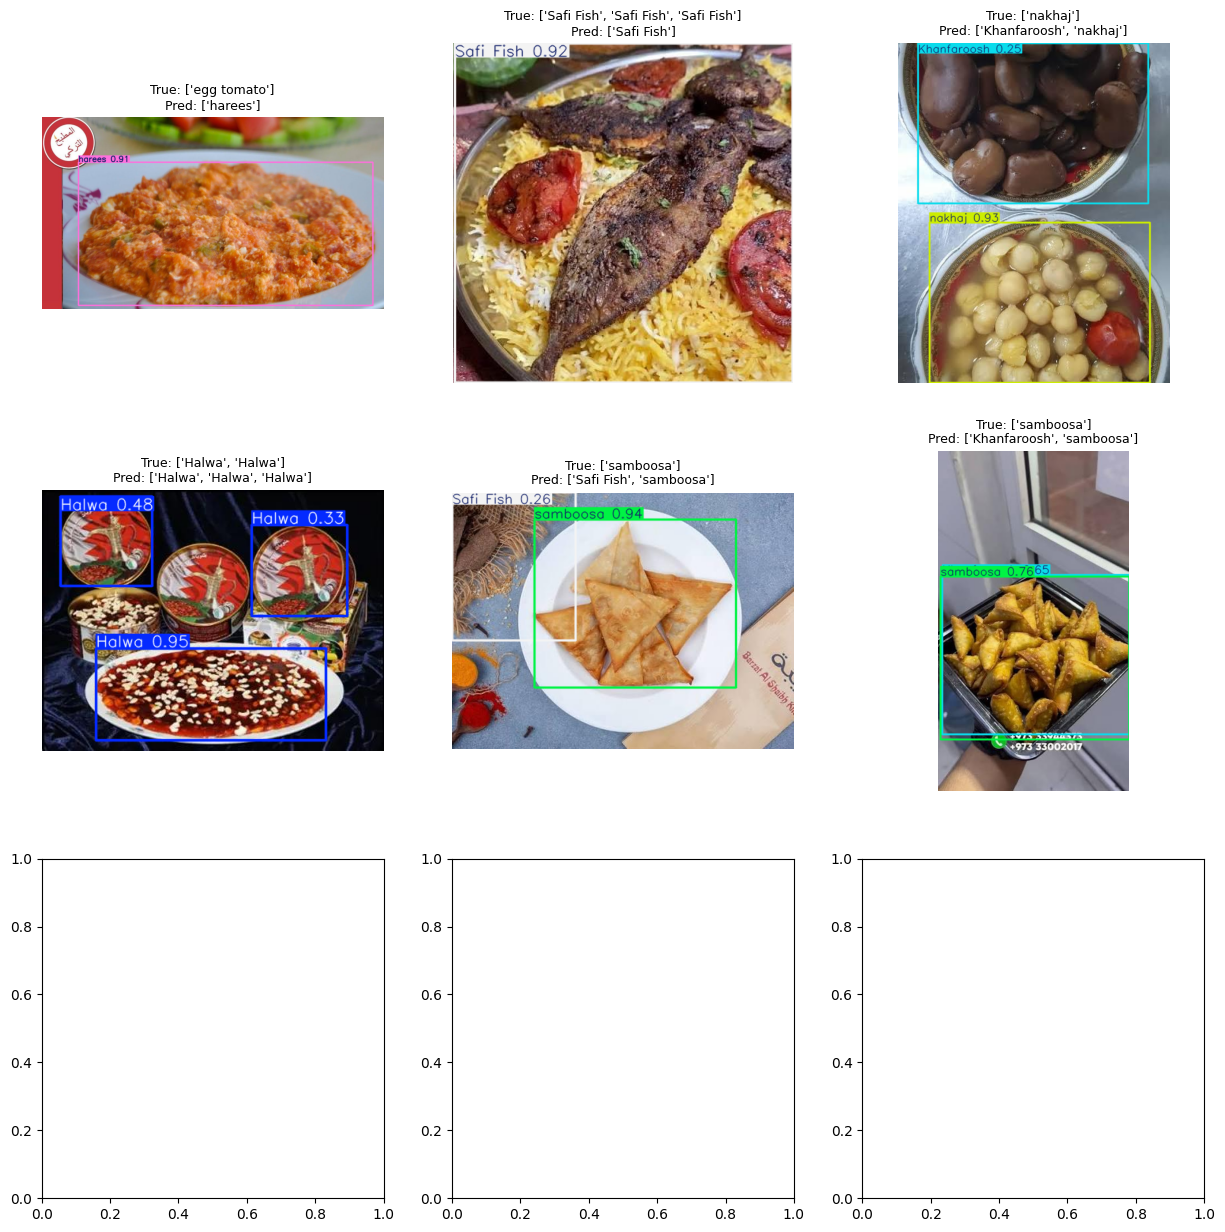

In [ ]:
import matplotlib.pyplot as plt

wrong = []
for r in fintuned_model_2.predict("/content/Bahrain_Foods-2/test/images", stream=True, verbose=False):
    lbl = r.path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    true = sorted(r.names[int(l.split()[0])] for l in open(lbl))
    pred = sorted(r.names[int(c)] for c in r.boxes.cls)
    if true != pred:
        wrong.append((r.plot()[..., ::-1], f"True: {true}\nPred: {pred}"))

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for ax, (img, title) in zip(axes.flat, wrong[:9]):
    ax.imshow(img); ax.set_title(title, fontsize=9); ax.axis("off")
plt.savefig("wrong_predictions.png")